In [1]:
import cv2

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cbook import get_sample_data
from PIL import Image

In [2]:
def show_images(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 3.5), layout="constrained")
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.show()



image_path = get_sample_data("grace_hopper.jpg", asfileobj=False)
with Image.open(image_path) as source:
    image = np.asarray(source.convert("L"))

image_float = image.astype(np.float32)

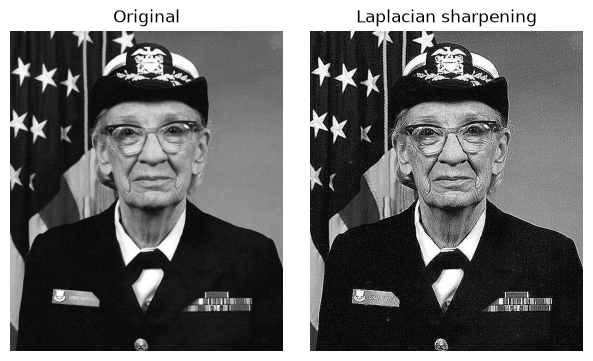

In [3]:
# Question 1
laplacian = cv2.Laplacian(image_float, cv2.CV_32F)
laplacian_sharp = np.clip(image_float - laplacian, 0, 255)
show_images((image, laplacian_sharp), ("Original", "Laplacian sharpening"))

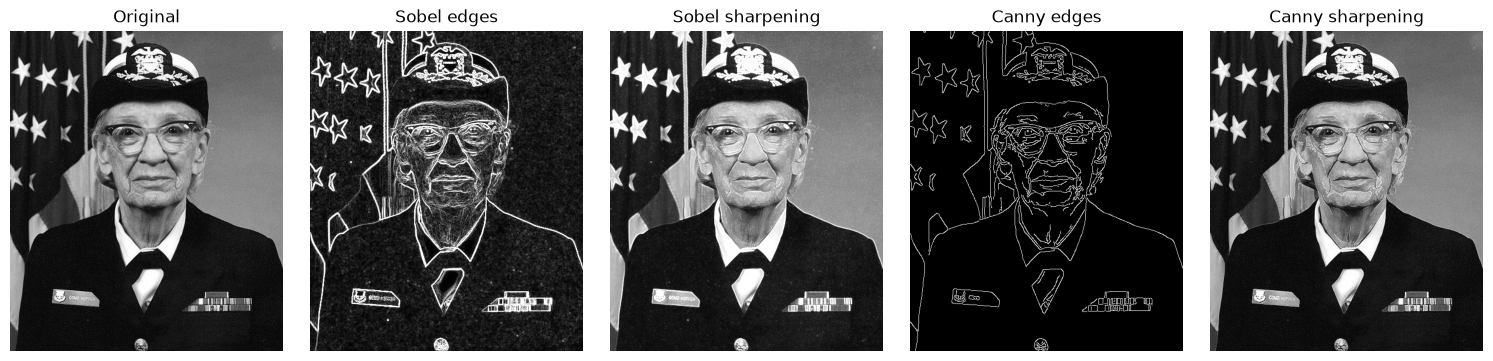

In [4]:
# Question 2
gradient_x = cv2.Sobel(image_float, cv2.CV_32F, 1, 0, ksize=3)
gradient_y = cv2.Sobel(image_float, cv2.CV_32F, 0, 1, ksize=3)
sobel_edges = cv2.magnitude(gradient_x, gradient_y)
sobel_sharp = np.clip(image_float + 0.25 * sobel_edges, 0, 255)

canny_edges = cv2.Canny(cv2.GaussianBlur(image, (5, 5), 1), 50, 150)
canny_sharp = np.clip(image_float + 0.25 * canny_edges, 0, 255)
show_images(
    (image, sobel_edges, sobel_sharp, canny_edges, canny_sharp),
    ("Original", "Sobel edges", "Sobel sharpening", "Canny edges", "Canny sharpening"),
)

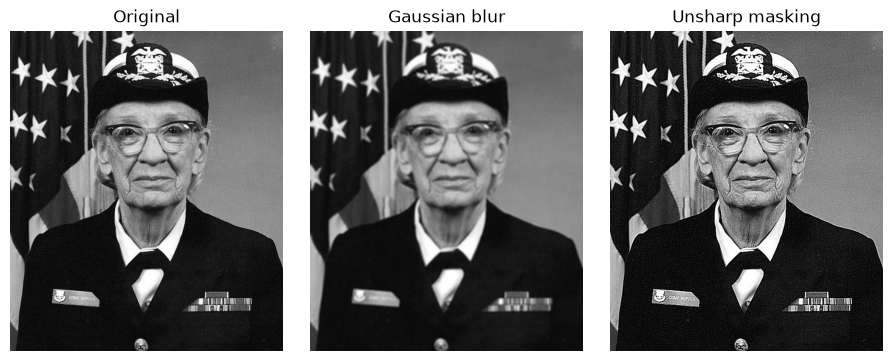

In [5]:
# Question 3
blurred = cv2.GaussianBlur(image_float, (5, 5), sigmaX=3)
detail = image_float - blurred
unsharp = np.clip(image_float + detail, 0, 255)
show_images((image, blurred, unsharp), ("Original", "Gaussian blur", "Unsharp masking"))